# Phần 1 · Notebook gốc của Kiên

Mở file bằng Colab, bật **Runtime → Change runtime type → GPU**, rồi chọn **Run all**.
Các cell và kết quả có sẵn trong phần 1 lấy nguyên từ `filecodegpukaggle.ipynb`
của nhánh `kien`. Những output có sẵn ở đây là kết quả Kiên đã chạy trên Tesla T4.
Thuật toán CPU và CUDA đã có trong notebook, nên có thể mở trực tiếp một file này.
Phần 2 bên dưới chạy lại các phép kiểm tra và xuất số liệu riêng.

Nếu môi trường báo thiếu thư viện, chạy `%pip install numpy scikit-learn matplotlib pandas numba`
trong một cell đầu notebook, rồi khởi động lại phiên nếu được yêu cầu.

# Đánh giá & Kiểm thử Thuật toán KudaNN (KNN Song song hóa trên CUDA/GPU)

Notebook này thực hiện các bước kiểm chứng và benchmark theo đúng quy trình trong báo cáo *"Paralleled K-Nearest Neighbors Algorithm"*:
1. **Kiểm tra môi trường phần cứng (GPU/CUDA) & Thư viện**.
2. **Kiểm thử tính đúng đắn (Correctness Test)** trên tập dữ liệu Iris (so sánh `SequentialKNN`, `CudaKNN` với `scikit-learn` baseline).
3. **Đo thời gian thực thi (CPU vs CUDA)** theo các kích thước mẫu tăng dần (`728`, `2912`, `3751`, `5824`, `7111`, `11648`).
4. **Tính toán & vẽ biểu đồ Hệ số tăng tốc (Acceleration)** của CUDA so với CPU.
5. **Khảo sát cấu hình số lượng Threads/Block** (`16`, `32`, `64`, `128`, `256`) trên tập dữ liệu cố định.

# chuẩn bị

In [1]:
import time
import math
import numpy as np
from numba import cuda
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

# --- 1. Sequential KNN & Sklearn Baseline ---
class SequentialKNN:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X_train, y_train):
        self.X_train = np.array(X_train)
        self.y_train = np.array(y_train)
        return self

    def _predict_single(self, x):
        distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))
        sorted_indices = np.argsort(distances)
        k_indices = sorted_indices[:self.k]
        k_nearest_labels = self.y_train[k_indices]
        vals, counts = np.unique(k_nearest_labels, return_counts=True)
        return vals[np.argmax(counts)]

    def predict(self, X_test):
        X_test = np.array(X_test)
        return np.array([self._predict_single(x) for x in X_test])


class SklearnKNNBaseline:
    def __init__(self, k=3):
        self.model = KNeighborsClassifier(n_neighbors=k)

    def fit(self, X_train, y_train):
        self.model.fit(X_train, y_train)
        return self

    def predict(self, X_test):
        return self.model.predict(X_test)


# --- 2. CUDA KNN Kernel & Manager ---
@cuda.jit
def knn_cuda_kernel(X_train, y_train, n_train, X_test, n_test, n_features, k, predictions, dist_buffer, label_buffer):
    idx = cuda.grid(1)
    if idx < n_test:
        for i in range(n_train):
            dist = 0.0
            for f in range(n_features):
                diff = X_train[i, f] - X_test[idx, f]
                dist += diff * diff
            # Dùng trực tiếp math.sqrt (numba hỗ trợ math.sqrt trong cuda mode)
            dist_buffer[idx, i] = math.sqrt(dist)
            label_buffer[idx, i] = y_train[i]

        for i in range(k):
            min_idx = i
            for j in range(i + 1, n_train):
                if dist_buffer[idx, j] < dist_buffer[idx, min_idx]:
                    min_idx = j
            if min_idx != i:
                tmp_dist = dist_buffer[idx, i]
                dist_buffer[idx, i] = dist_buffer[idx, min_idx]
                dist_buffer[idx, min_idx] = tmp_dist
                tmp_lbl = label_buffer[idx, i]
                label_buffer[idx, i] = label_buffer[idx, min_idx]
                label_buffer[idx, min_idx] = tmp_lbl

        best_label = label_buffer[idx, 0]
        best_count = 0
        for i in range(k):
            current_label = label_buffer[idx, i]
            count = 0
            for j in range(k):
                if label_buffer[idx, j] == current_label:
                    count += 1
            if count > best_count:
                best_count = count
                best_label = current_label

        predictions[idx] = best_label


class CudaKNN:
    def __init__(self, k=3, threads_per_block=256):
        self.k = k
        self.threads_per_block = threads_per_block
        self.X_train = None
        self.y_train = None

    def fit(self, X_train, y_train):
        self.X_train = np.ascontiguousarray(X_train, dtype=np.float32)
        self.y_train = np.ascontiguousarray(y_train, dtype=np.int32)
        return self

    def predict(self, X_test):
        if not cuda.is_available():
            raise RuntimeError("Không tìm thấy GPU hỗ trợ CUDA!")
        X_test = np.ascontiguousarray(X_test, dtype=np.float32)
        n_train, n_features = self.X_train.shape
        n_test = X_test.shape[0]

        d_X_train = cuda.to_device(self.X_train)
        d_y_train = cuda.to_device(self.y_train)
        d_X_test = cuda.to_device(X_test)
        d_predictions = cuda.device_array(n_test, dtype=np.int32)
        d_dist_buffer = cuda.device_array((n_test, n_train), dtype=np.float32)
        d_label_buffer = cuda.device_array((n_test, n_train), dtype=np.int32)

        blocks = (n_test + self.threads_per_block - 1) // self.threads_per_block
        knn_cuda_kernel[blocks, self.threads_per_block](
            d_X_train, d_y_train, n_train, d_X_test, n_test, n_features,
            self.k, d_predictions, d_dist_buffer, d_label_buffer
        )
        cuda.synchronize()
        return d_predictions.copy_to_host()


# --- 3. Unified Interface ---
class KudaNNClassifier:
    def __init__(self, k=3, mode="cuda", threads_per_block=256):
        self.k = k
        self.mode = mode.lower()
        self.threads_per_block = threads_per_block

        if self.mode == "cuda":
            self._model = CudaKNN(k=self.k, threads_per_block=self.threads_per_block)
        elif self.mode == "cpu":
            self._model = SequentialKNN(k=self.k)
        elif self.mode == "sklearn":
            self._model = SklearnKNNBaseline(k=self.k)
        else:
            raise ValueError("Mode không hợp lệ! Chọn 'cuda', 'cpu' hoặc 'sklearn'.")

    def fit(self, X_train, y_train):
        self._model.fit(X_train, y_train)
        return self

    def predict(self, X_test):
        return self._model.predict(X_test)

    def predict_with_timing(self, X_test):
        start = time.perf_counter()
        preds = self.predict(X_test)
        return preds, time.perf_counter() - start

    def score(self, X_test, y_test):
        return accuracy_score(y_test, self.predict(X_test))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda
from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import train_test_split

# Kiểm tra trạng thái GPU/CUDA trên Kaggle
print("CUDA Available:", cuda.is_available())
if cuda.is_available():
    device = cuda.get_current_device()
    # Sửa lại ở đây: gọi trực tiếp device.name vì nó đã là chuỗi (str)
    print("Device Name:", device.name)
    print("Compute Capability:", device.compute_capability)
    print("Multiprocessor Count:", device.MULTIPROCESSOR_COUNT)

# --- Kiểm tra nhanh tính đúng đắn với KudaNNClassifier ---
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=42
)

# Khởi tạo mô hình chạy trên CUDA GPU
clf = KudaNNClassifier(k=3, mode='cuda')
clf.fit(X_train, y_train)

# Dự đoán và đo thời gian
preds, t_cuda = clf.predict_with_timing(X_test)
acc = clf.score(X_test, y_test)

print(f"\n[KudaNN CUDA Test]")
print(f"Accuracy: {acc:.4f}")
print(f"Execution Time: {t_cuda:.6f} seconds")

CUDA Available: True
Device Name: NVIDIA L4
Compute Capability: ComputeCapability(major=8, minor=9)
Multiprocessor Count: 58


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))



[KudaNN CUDA Test]
Accuracy: 1.0000
Execution Time: 1.675383 seconds


## 1. Kiểm thử tính đúng đắn trên tập dữ liệu Iris
Đảm bảo cả phiên bản tuần tự (CPU) và song song (CUDA) đều cho độ chính xác tương đương chuẩn `scikit-learn`.

In [3]:
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42
)

K = 3

# 1. Sklearn Baseline
clf_sklearn = KudaNNClassifier(k=K, mode='sklearn').fit(X_train, y_train)
preds_sklearn, t_sklearn = clf_sklearn.predict_with_timing(X_test)

# 2. Sequential CPU
clf_cpu = KudaNNClassifier(k=K, mode='cpu').fit(X_train, y_train)
preds_cpu, t_cpu = clf_cpu.predict_with_timing(X_test)

# 3. KudaNN (CUDA GPU)
# Chạy warm-up 1 lần để Numba biên dịch JIT kernel trước khi đo giờ thực tế
clf_cuda = KudaNNClassifier(k=K, mode='cuda', threads_per_block=256).fit(X_train, y_train)
_ = clf_cuda.predict(X_test)
preds_cuda, t_cuda = clf_cuda.predict_with_timing(X_test)

print(f"Sklearn Accuracy : {clf_sklearn.score(X_test, y_test):.6f} | Time: {t_sklearn:.6f}s")
print(f"CPU Seq Accuracy : {clf_cpu.score(X_test, y_test):.6f} | Time: {t_cpu:.6f}s")
print(f"CUDA GPU Accuracy: {clf_cuda.score(X_test, y_test):.6f} | Time: {t_cuda:.6f}s")
print("Kết quả dự đoán CPU và CUDA trùng khớp hoàn toàn:", np.array_equal(preds_cpu, preds_cuda))

Sklearn Accuracy : 1.000000 | Time: 0.002209s
CPU Seq Accuracy : 1.000000 | Time: 0.002311s
CUDA GPU Accuracy: 1.000000 | Time: 0.001516s
Kết quả dự đoán CPU và CUDA trùng khớp hoàn toàn: True


## 2. Benchmark CPU vs CUDA theo kích thước tập dữ liệu (Sample Size)
Sử dụng các mốc kích thước mẫu tương tự mục III.C.2 trong báo cáo: `[728, 2912, 3751, 5824, 7111, 11648]`.

In [4]:
sample_sizes = [728, 2912, 3751, 5824, 7111, 11648]
cpu_times = []
cuda_times = []
accelerations = []

for size in sample_sizes:
    X_syn, y_syn = make_classification(
        n_samples=size, n_features=10, n_informative=6, n_classes=3, random_state=42
    )
    X_tr, X_te, y_tr, y_te = train_test_split(X_syn, y_syn, test_size=0.3, random_state=42)

    # Đo thời gian CPU
    model_cpu = KudaNNClassifier(k=5, mode='cpu').fit(X_tr, y_tr)
    _, t_c = model_cpu.predict_with_timing(X_te)

    # Đo thời gian CUDA
    model_cuda = KudaNNClassifier(k=5, mode='cuda', threads_per_block=256).fit(X_tr, y_tr)
    _, t_g = model_cuda.predict_with_timing(X_te)

    acc = t_c / t_g
    cpu_times.append(t_c)
    cuda_times.append(t_g)
    accelerations.append(acc)
    print(f"Size={size:5d} | CPU: {t_c:7.4f}s | CUDA: {t_g:7.4f}s | Acceleration: {acc:6.2f}x")

Size=  728 | CPU:  0.0178s | CUDA:  0.0033s | Acceleration:   5.38x
Size= 2912 | CPU:  0.1768s | CUDA:  0.0091s | Acceleration:  19.51x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 5 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Size= 3751 | CPU:  0.2879s | CUDA:  0.0111s | Acceleration:  25.96x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 7 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Size= 5824 | CPU:  0.6804s | CUDA:  0.0153s | Acceleration:  44.41x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 9 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Size= 7111 | CPU:  0.9799s | CUDA:  0.0206s | Acceleration:  47.63x
Size=11648 | CPU:  2.5893s | CUDA:  0.0424s | Acceleration:  61.01x


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 14 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


## 3. Trực quan hóa kết quả (Biểu đồ Time & Acceleration)

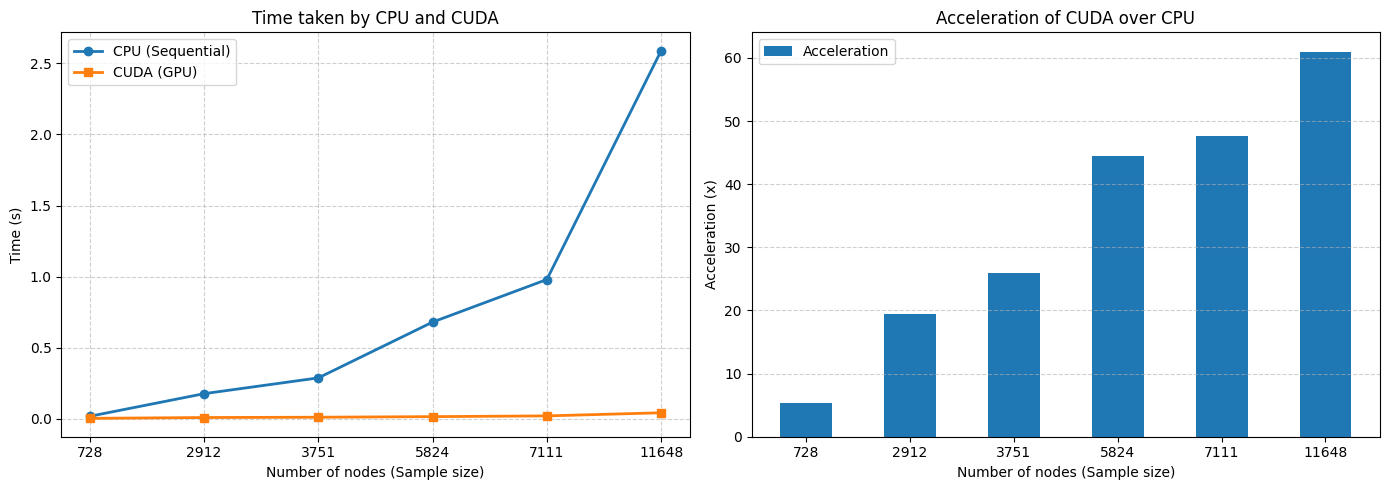

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Thời gian thực thi CPU vs CUDA (Tương ứng Fig. 4)
x_labels = [str(s) for s in sample_sizes]
axes[0].plot(x_labels, cpu_times, marker='o', label='CPU (Sequential)', linewidth=2)
axes[0].plot(x_labels, cuda_times, marker='s', label='CUDA (GPU)', linewidth=2)
axes[0].set_title('Time taken by CPU and CUDA')
axes[0].set_xlabel('Number of nodes (Sample size)')
axes[0].set_ylabel('Time (s)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Biểu đồ 2: Hệ số tăng tốc Acceleration (Tương ứng Fig. 5)
axes[1].bar(x_labels, accelerations, color='tab:blue', width=0.5, label='Acceleration')
axes[1].set_title('Acceleration of CUDA over CPU')
axes[1].set_xlabel('Number of nodes (Sample size)')
axes[1].set_ylabel('Acceleration (x)')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 4. Khảo sát cấu hình số Threads trên mỗi Block
Cố định tập dữ liệu 7111 mẫu, thử nghiệm với các mức `threads_per_block = [16, 32, 64, 128, 256]` (Tương ứng Fig. 6).

Threads per block =  16 -> Time: 0.01330s
Threads per block =  32 -> Time: 0.01610s
Threads per block =  64 -> Time: 0.01382s
Threads per block = 128 -> Time: 0.01742s
Threads per block = 256 -> Time: 0.01843s


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 67 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 34 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 17 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


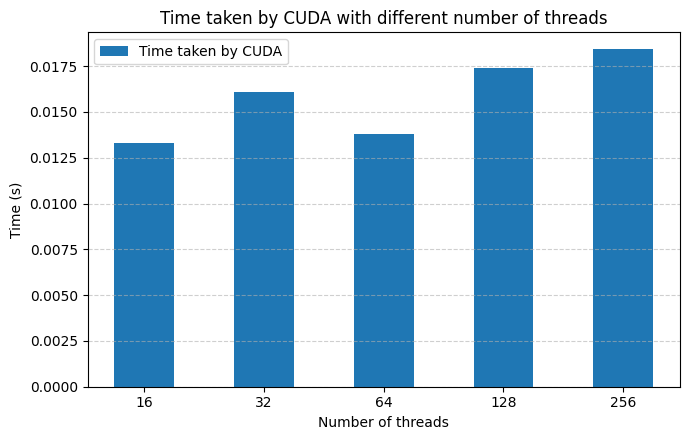

In [6]:
thread_configs = [16, 32, 64, 128, 256]
thread_times = []

X_7111, y_7111 = make_classification(
    n_samples=7111, n_features=10, n_informative=6, n_classes=3, random_state=42
)
X_tr, X_te, y_tr, y_te = train_test_split(X_7111, y_7111, test_size=0.3, random_state=42)

for tpb in thread_configs:
    model = KudaNNClassifier(k=5, mode='cuda', threads_per_block=tpb).fit(X_tr, y_tr)
    _, elapsed = model.predict_with_timing(X_te)
    thread_times.append(elapsed)
    print(f"Threads per block = {tpb:3d} -> Time: {elapsed:.5f}s")

plt.figure(figsize=(7, 4.5))
plt.bar([str(t) for t in thread_configs], thread_times, color='tab:blue', width=0.5, label='Time taken by CUDA')
plt.title('Time taken by CUDA with different number of threads')
plt.xlabel('Number of threads')
plt.ylabel('Time (s)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Phần 2 · Kiểm thử và tái hiện thí nghiệm

Chạy các cell từ đầu để nạp `KudaNNClassifier` của Kiên. Phần này kiểm tra nhãn dự đoán
với đáp án tính tay và scikit-learn, kiểm tra Iris theo từng mẫu, rồi đo lặp lại để so sánh
với các hình 3–6 trong paper. Bảng kết quả và biểu đồ được lưu trong `results_thanh_vien_2/`.

In [7]:
from pathlib import Path
from time import perf_counter
import platform

import pandas as pd
from IPython.display import display

OUTPUT_DIR = Path("results_thanh_vien_2")
OUTPUT_DIR.mkdir(exist_ok=True)

if not cuda.is_available():
    raise RuntimeError("Hãy bật GPU trong Colab rồi chạy lại notebook từ đầu.")

gpu_device = cuda.get_current_device()
gpu_name = gpu_device.name
if isinstance(gpu_name, bytes):
    gpu_name = gpu_name.decode("utf-8")

environment = pd.DataFrame([{
    "platform": platform.platform(),
    "cpu": platform.processor() or platform.machine(),
    "gpu": gpu_name,
    "compute_capability": str(gpu_device.compute_capability),
    "python": platform.python_version(),
}])
environment.to_csv(OUTPUT_DIR / "environment.csv", index=False)
display(environment)

,platform,cpu,gpu,compute_capability,python
0,Linux-6.6.159+-x86_64-with-glibc2.39,x86_64,NVIDIA L4,"ComputeCapability(major=8, minor=9)",3.13.16


## 2.1 · Kiểm tra tính đúng với đáp án biết trước

Bốn điểm huấn luyện nằm trên trục x, có nhãn lần lượt `0, 0, 1, 1`. Hai điểm truy vấn
nằm gần hai đầu. Với `k=1` và `k=3`, nhãn mong đợi lần lượt là 0 và 1.
Khoảng cách và phiếu đa số được chọn để tránh trường hợp hòa.

In [8]:
def check_known_examples():
    x_train = np.array([[0, 0], [2, 0], [5, 0], [9, 0]], dtype=np.float32)
    y_train = np.array([0, 0, 1, 1], dtype=np.int32)
    x_test = np.array([[1.5, 0], [8, 0]], dtype=np.float32)
    expected = np.array([0, 1])
    rows = []
    for k in (1, 3):
        for mode in ("cpu", "cuda", "sklearn"):
            model = KudaNNClassifier(k=k, mode=mode).fit(x_train, y_train)
            predicted = model.predict(x_test)
            for query_id, (actual, wanted) in enumerate(zip(predicted, expected, strict=True)):
                rows.append({
                    "mode": mode, "k": k, "query_id": query_id,
                    "expected": wanted, "predicted": actual, "pass": actual == wanted,
                })
    return pd.DataFrame(rows)


known_checks = check_known_examples()
display(known_checks)
known_checks.to_csv(OUTPUT_DIR / "correctness.csv", index=False)
assert known_checks["pass"].all(), "Có ca sai. Xem bảng correctness trước khi benchmark."

,mode,k,query_id,expected,predicted,pass
0,cpu,1,0,0,0,True
1,cpu,1,1,1,1,True
2,cuda,1,0,0,0,True
3,cuda,1,1,1,1,True
4,sklearn,1,0,0,0,True
5,sklearn,1,1,1,1,True
6,cpu,3,0,0,0,True
7,cpu,3,1,1,1,True
8,cuda,3,0,0,0,True
9,cuda,3,1,1,1,True


## 2.2 · Iris và hình 3

Dùng cùng cách chia 80/20, seed 42 và `k=3` như cell Iris của Kiên. Ba thuật toán
nhận cùng dữ liệu `float32`. So sánh accuracy với nhãn thật và đối chiếu nhãn từng mẫu.
Các hàng lệch, nếu có, được in ra và lưu trong bảng chi tiết.

In [9]:
def evaluate_iris(k=3, seed=42):
    iris_data = load_iris()
    train_ids, test_ids = train_test_split(
        np.arange(len(iris_data.target)), test_size=0.2, random_state=seed
    )
    features = iris_data.data.astype(np.float32)
    labels = iris_data.target
    predictions = {}
    for mode in ("cpu", "cuda", "sklearn"):
        model = KudaNNClassifier(k=k, mode=mode).fit(features[train_ids], labels[train_ids])
        predictions[mode] = model.predict(features[test_ids])

    details = pd.DataFrame({"sample_id": test_ids, "true_label": labels[test_ids], **predictions})
    details["cpu_gpu_match"] = details["cpu"] == details["cuda"]
    details["all_match"] = details["cpu_gpu_match"] & (details["cpu"] == details["sklearn"])
    summary = pd.DataFrame([{
        "k": k,
        "seed": seed,
        "n_test": len(details),
        **{f"{mode}_accuracy": float((details[mode] == details["true_label"]).mean())
           for mode in predictions},
        "cpu_gpu_mismatches": int((~details["cpu_gpu_match"]).sum()),
        "all_model_mismatches": int((~details["all_match"]).sum()),
    }])
    return summary, details


iris_summary, iris_details = evaluate_iris()
display(iris_summary)
display(iris_details.loc[~iris_details["all_match"]])
iris_summary.to_csv(OUTPUT_DIR / "iris_summary.csv", index=False)
iris_details.to_csv(OUTPUT_DIR / "iris_predictions.csv", index=False)

,k,seed,n_test,cpu_accuracy,cuda_accuracy,sklearn_accuracy,cpu_gpu_mismatches,all_model_mismatches
0,3,42,30,1.0,1.0,1.0,0,0


,sample_id,true_label,cpu,cuda,sklearn,cpu_gpu_match,all_match


## 2.3 · Hàm benchmark để thành viên 3 dùng lại

`run_benchmark()` chạy hai phép đo. Phép thứ nhất đổi kích thước dữ liệu và giữ
256 threads/block. Phép thứ hai giữ 7.111 mẫu và đổi threads/block. Mỗi cấu hình
warm-up một lần rồi đo trung vị của ba lần chạy `fit + predict`. Phép đo GPU gồm
cấp phát, truyền dữ liệu và sao chép dự đoán về CPU. Thời gian tạo/chia dữ liệu
nằm ngoài phép đo.

Các mốc lấy từ mục III.C của paper. Bản gốc của Kiên có thêm mốc 2.912. Phần 2
dùng các mốc liệt kê trong mục này. Dữ liệu tổng hợp theo cách của Kiên với
10 đặc trưng, chia train/test 70/30 và `k=5`. Khi báo cáo, ghi đây là so sánh
xu hướng trên dữ liệu tổng hợp với bản triển khai Python/Numba.

[Nguồn paper, mục III.C và IV.A](https://www.researchgate.net/publication/368586243_Paralleled_K-Nearest_Neighbors_Algorithm)

In [10]:
PAPER_SIZES = (728, 3751, 5824, 7111, 11648)
PAPER_THREADS = (16, 32, 64, 128, 256)


def benchmark_data(size, seed):
    features, labels = make_classification(
        n_samples=size, n_features=10, n_informative=6, n_classes=3, random_state=seed
    )
    return train_test_split(
        features.astype(np.float32), labels.astype(np.int32),
        test_size=0.3, random_state=seed,
    )


def measure_fit_predict(data, mode, k, threads_per_block, repeats):
    x_train, x_test, y_train, _ = data
    model = KudaNNClassifier(k=k, mode=mode, threads_per_block=threads_per_block)
    model.fit(x_train, y_train).predict(x_test)
    elapsed = []
    for _ in range(repeats):
        start = perf_counter()
        model.fit(x_train, y_train).predict(x_test)
        elapsed.append(perf_counter() - start)
    return float(np.median(elapsed))


def run_benchmark(sizes=PAPER_SIZES, thread_configs=PAPER_THREADS, *,
                  fixed_size=7111, repeats=3, k=5, seed=42):
    # Trả về hai DataFrame: thời gian theo số mẫu và thời gian theo threads/block.
    if repeats < 1:
        raise ValueError("repeats phải từ 1 trở lên.")
    if not cuda.is_available():
        raise RuntimeError("Bật CUDA trước khi chạy benchmark.")

    size_rows = []
    for size in sizes:
        data = benchmark_data(size, seed)
        cpu_s = measure_fit_predict(data, "cpu", k, 256, repeats)
        gpu_s = measure_fit_predict(data, "cuda", k, 256, repeats)
        size_rows.append({
            "samples": size, "train_samples": len(data[0]), "test_samples": len(data[1]),
            "threads_per_block": 256, "cpu_s": cpu_s, "gpu_s": gpu_s,
            "speedup": cpu_s / gpu_s, "repeats": repeats, "k": k, "seed": seed,
        })

    thread_rows = []
    fixed_data = benchmark_data(fixed_size, seed)
    for threads in thread_configs:
        gpu_s = measure_fit_predict(fixed_data, "cuda", k, threads, repeats)
        thread_rows.append({
            "samples": fixed_size, "threads_per_block": threads, "gpu_s": gpu_s,
            "repeats": repeats, "k": k, "seed": seed,
        })
    return pd.DataFrame(size_rows), pd.DataFrame(thread_rows)

,samples,train_samples,test_samples,threads_per_block,cpu_s,gpu_s,speedup,repeats,k,seed
0,728,509,219,256,0.015772,0.002651,5.948420,3,5,42
1,3751,2625,1126,256,0.236791,0.009972,23.746617,3,5,42
2,5824,4076,1748,256,0.546682,0.014578,37.500493,3,5,42
3,7111,4977,2134,256,0.817196,0.020289,40.278552,3,5,42
4,11648,8153,3495,256,2.181922,0.041610,52.437254,3,5,42


,samples,threads_per_block,gpu_s,repeats,k,seed
0,7111,16,0.016246,3,5,42
1,7111,32,0.013782,3,5,42
2,7111,64,0.013816,3,5,42
3,7111,128,0.017131,3,5,42
4,7111,256,0.020205,3,5,42


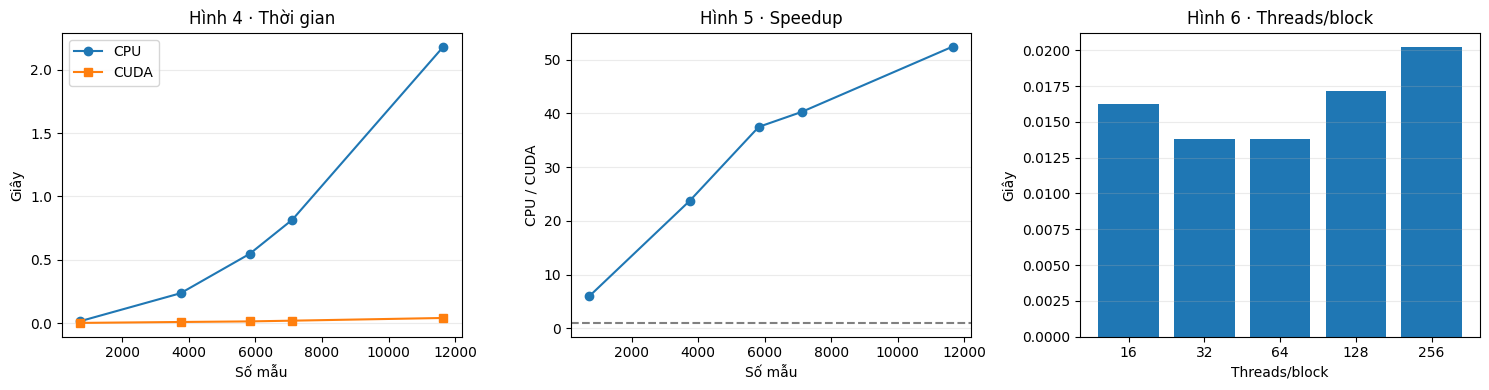

In [11]:
size_results, thread_results = run_benchmark()
display(size_results)
display(thread_results)
size_results.to_csv(OUTPUT_DIR / "benchmark_sizes.csv", index=False)
thread_results.to_csv(OUTPUT_DIR / "benchmark_threads.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(size_results["samples"], size_results["cpu_s"], "o-", label="CPU")
axes[0].plot(size_results["samples"], size_results["gpu_s"], "s-", label="CUDA")
axes[0].set(title="Hình 4 · Thời gian", xlabel="Số mẫu", ylabel="Giây")
axes[0].legend()
axes[1].plot(size_results["samples"], size_results["speedup"], "o-")
axes[1].axhline(1, linestyle="--", color="gray")
axes[1].set(title="Hình 5 · Speedup", xlabel="Số mẫu", ylabel="CPU / CUDA")
axes[2].bar(thread_results["threads_per_block"].astype(str), thread_results["gpu_s"])
axes[2].set(title="Hình 6 · Threads/block", xlabel="Threads/block", ylabel="Giây")
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "paper_comparison.png", dpi=160)
plt.show()

## 2.4 · Đối chiếu xu hướng với paper

Hình 3 báo điểm phân loại Iris hoàn hảo. Hình 4–5 cho thấy lợi thế CUDA rõ hơn ở
tập lớn. Hình 6 cho thấy tăng threads/block có thể làm thời gian tăng. Cell dưới
đây đối chiếu từng ý với số liệu vừa đo. Nếu CPU và GPU dự đoán khác nhau trên
Iris, xem bảng theo từng mẫu. Hai bản của Kiên có thể xử lý hòa phiếu khác nhau.

[Nguồn paper, mục III.C và IV.A](https://www.researchgate.net/publication/368586243_Paralleled_K-Nearest_Neighbors_Algorithm)

In [12]:
iris_row = iris_summary.iloc[0]
ordered_sizes = size_results.sort_values("samples")
smallest, largest = ordered_sizes.iloc[0], ordered_sizes.iloc[-1]
best_threads = thread_results.loc[thread_results["gpu_s"].idxmin()]
max_threads = thread_results.loc[thread_results["threads_per_block"].idxmax()]
same_iris = int(iris_row["n_test"] - iris_row["cpu_gpu_mismatches"])

comparison = pd.DataFrame([
    {
        "paper": "Hình 3 · Iris",
        "kết quả nhóm": (
            f"CPU {iris_row['cpu_accuracy']:.1%}, CUDA {iris_row['cuda_accuracy']:.1%}. "
            f"Hai bên trùng {same_iris}/{int(iris_row['n_test'])} nhãn."
        ),
        "đối chiếu": "Cùng đạt 100%" if (
            iris_row["cpu_accuracy"] == iris_row["cuda_accuracy"] == 1
        ) else "Accuracy khác kết quả paper.",
    },
    {
        "paper": "Hình 4–5 · CPU/GPU theo số mẫu",
        "kết quả nhóm": (
            f"{int(smallest['samples'])} mẫu: {smallest['speedup']:.2f}×. "
            f"{int(largest['samples'])} mẫu: {largest['speedup']:.2f}×."
        ),
        "đối chiếu": "Lợi thế CUDA tăng giữa hai đầu dải đo." if (
            largest["speedup"] > max(1, smallest["speedup"])
        ) else "Hai đầu dải đo chưa cho thấy lợi thế CUDA tăng như paper.",
    },
    {
        "paper": "Hình 6 · Threads/block",
        "kết quả nhóm": (
            f"Nhanh nhất: {int(best_threads['threads_per_block'])} threads/block "
            f"({best_threads['gpu_s'] * 1000:.2f} ms)."
        ),
        "đối chiếu": "Có cấu hình ít threads chạy nhanh hơn cấu hình nhiều nhất." if (
            best_threads["gpu_s"] < max_threads["gpu_s"]
        ) else "Cấu hình nhiều threads nhất đạt thời gian tốt nhất hoặc đồng hạng.",
    },
])
display(comparison)
comparison.to_csv(OUTPUT_DIR / "paper_comparison.csv", index=False)
print(f"Đã lưu bảng và biểu đồ tại: {OUTPUT_DIR.resolve()}")

,paper,kết quả nhóm,đối chiếu
0,Hình 3 · Iris,"CPU 100.0%, CUDA 100.0%. Hai bên trùng 30/30 n...",Cùng đạt 100%
1,Hình 4–5 · CPU/GPU theo số mẫu,728 mẫu: 5.95×. 11648 mẫu: 52.44×.,Lợi thế CUDA tăng giữa hai đầu dải đo.
2,Hình 6 · Threads/block,Nhanh nhất: 32 threads/block (13.78 ms).,Có cấu hình ít threads chạy nhanh hơn cấu hình...


Đã lưu bảng và biểu đồ tại: /content/results_thanh_vien_2
